1990 -> 559 kayit
1991 -> 928 kayit
1992 -> 583 kayit
1993 -> 2328 kayit
1994 -> 2628 kayit
1995 -> 879 kayit
1996 -> 557 kayit
1997 -> 315 kayit
1998 -> 1114 kayit
1999 -> 1344 kayit
2000 -> 311 kayit
2001 -> 466 kayit
2002 -> 216 kayit
2003 -> 315 kayit
2004 -> 971 kayit
2005 -> 1207 kayit
2006 -> 704 kayit
2007 -> 713 kayit
2008 -> 569 kayit
2009 -> 38 kayit
2010 -> 53 kayit
2011 -> 246 kayit
2012 -> 123 kayit
2013 -> 78 kayit
2014 -> 90 kayit
2015 -> 73 kayit
2016 -> 53 kayit
2017 -> 133 kayit
2018 -> 70 kayit
2019 -> 93 kayit
2020 -> 192 kayit
2021 -> 160 kayit
2022 -> 97 kayit
2023 -> 677 kayit
2024 -> 126 kayit
2025 -> 294 kayit
2026 -> 74 kayit
Toplam ham kayit: 19377
Temiz kayit: 19375
magType
md     9685
ml     5266
mb     3633
mwr     331
mww     177
mwc     126
m       112
mwb      21
Name: count, dtype: int64
6 Subat - 6 Mart 2023 kayit: 478
                         time  mag  \
18216 2023-02-06 01:17:34.342  7.8   
18316 2023-02-06 10:24:48.811  7.5   
18218 2023-02-06 01

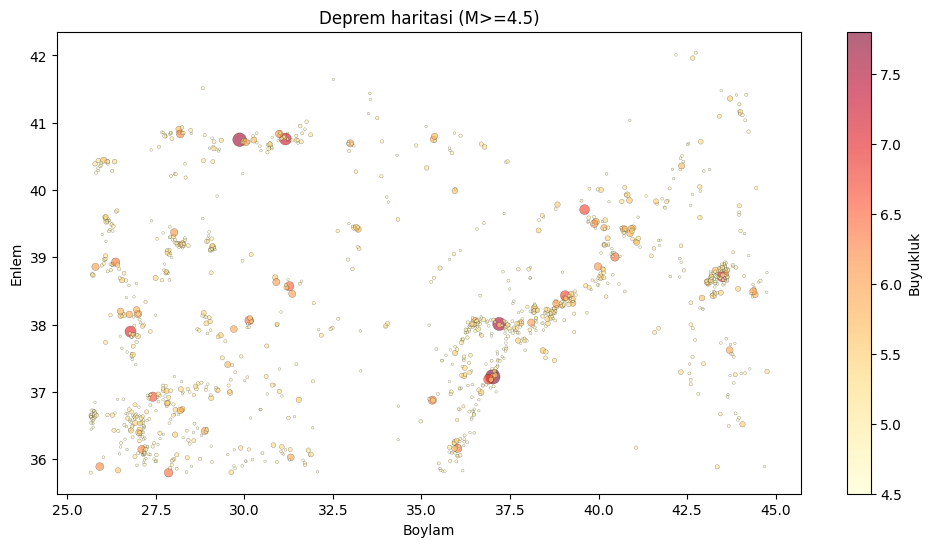

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import io, time, requests
import pandas as pd
import matplotlib.pyplot as plt

URL = "https://earthquake.usgs.gov/fdsnws/event/1/query"
PARAMS = {
    "format": "csv",
    "minlatitude": 35.8, "maxlatitude": 42.1,
    "minlongitude": 25.66, "maxlongitude": 44.8,
    "minmagnitude": 2.5, "orderby": "time-asc", "limit": 20000,
}

# --- 1) Veriyi yil yil cek ---
parcalar = []
for yil in range(1990, 2027):
    p = dict(PARAMS)
    p["starttime"] = f"{yil}-01-01"
    p["endtime"] = f"{yil+1}-01-01"
    try:
        r = requests.get(URL, params=p, timeout=60)
        r.raise_for_status()
        d = pd.read_csv(io.StringIO(r.text))
        parcalar.append(d)
        print(yil, "->", len(d), "kayit")
        if len(d) >= 20000:
            print("   UYARI: 20.000 siniri doldu, veri eksik olabilir!")
    except Exception as e:
        print(yil, "HATA:", e)
    time.sleep(0.5)

ham = pd.concat(parcalar, ignore_index=True)
print("Toplam ham kayit:", len(ham))

# --- 2) Temizle ---
df = ham[ham["type"] == "earthquake"]
df = df[["id", "time", "latitude", "longitude", "depth", "mag", "magType", "place"]]
df["time"] = pd.to_datetime(df["time"], utc=True).dt.tz_localize(None)
df["yil"] = df["time"].dt.year
df = df.dropna(subset=["latitude", "longitude", "depth", "mag"])
df = df.drop_duplicates(subset="id")
df = df[(df["mag"] >= 2.5) & (df["mag"] <= 10)]
df["depth"] = df["depth"].clip(lower=0)
df["magType"] = df["magType"].str.lower()
df = df.sort_values("time").reset_index(drop=True)
print("Temiz kayit:", len(df))
print(df["magType"].value_counts().head(8))

# --- 3) 6 Subat 2023 ---
subat = df[(df["time"] >= "2023-02-06") & (df["time"] < "2023-03-07")]
print("6 Subat - 6 Mart 2023 kayit:", len(subat))
print(subat.sort_values("mag", ascending=False).head(5)[["time", "mag", "place"]])

# --- 4) Harita ---
b = df[df["mag"] >= 4.5]
plt.figure(figsize=(12, 6))
sc = plt.scatter(b["longitude"], b["latitude"], c=b["mag"],
                 s=(b["mag"] - 3) ** 3, cmap="YlOrRd", alpha=0.6,
                 edgecolor="k", linewidth=0.2)
plt.colorbar(sc, label="Buyukluk")
plt.title("Deprem haritasi (M>=4.5)")
plt.xlabel("Boylam"); plt.ylabel("Enlem")
plt.show()

# --- 5) Kaydet ve indir ---
df.to_csv("deprem_temiz.csv", index=False)
from google.colab import files
files.download("deprem_temiz.csv")
